# 5.1 Logistic Regression — Verdeflor, Harry

HeatCast NCR · predicts `HeatLevelTomorrow` (next-day maximum heat index level) for the 16 Metro Manila cities.

**Rules followed (workspace 4.1):** the shared chronological split and gap (`ncr_preprocessing.prepare_dataset`), the same 5
expanding-window folds, the shared transformer (`make_preprocessor`, fitted inside each training fold), `random_state = 42`
and the shared scoring (`ncr_model_eval`). **The test partition is never used in this notebook**. Only the model chosen in
Section 6 is evaluated on it, once.

Primary metric used for tuning: **macro F1 over the classes present in each validation block** (proposed in 4.1; the group
still has to confirm it). Danger recall, Danger precision and the Danger false-alarm rate are reported next to it.

Run time: about 15 minutes on a laptop (about 50 configurations × 5 folds).

In [1]:
import json, os, sys, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().resolve()
if not (ROOT / "ncr_preprocessing.py").exists():   # opened from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import ncr_model_eval as E
import ncr_preprocessing as P

# Open group decision (workspace 4.3): "five_class" keeps the labels as built; "three_class" merges the rare classes.
# Feature sets the Streamlit app can collect from a user (4.3). "all_lags" (44 extra inputs) is tried for reference only.
APP_FEATURE_SETS = ["today", "hi_lags"]
TARGET_POLICY = os.environ.get("HEATCAST_TARGET_POLICY", "five_class")
RANDOM_STATE = P.RANDOM_STATE
OUT = ROOT / "results" / "logistic_regression" / TARGET_POLICY
OUT.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
pd.set_option("display.float_format", "{:.3f}".format)
print("scikit-learn", sklearn.__version__, "| target policy:", TARGET_POLICY, "| outputs ->", OUT.relative_to(ROOT))

scikit-learn 1.9.1 | target policy: five_class | outputs -> results\logistic_regression\five_class


## 1. Data, split and folds (shared, from Section 4)

In [2]:
prep = P.prepare_dataset(ROOT / "data/ncr/output/ph_heat_index_next_day.csv", target_policy=TARGET_POLICY)
LABELS = prep.class_labels
print(prep.counts)
print("test starts", prep.test_start.date(), "- test rows are NOT used below")
P.class_count_table(prep)

D:\Claude\heatcast-ph\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'rows_in': 64240, 'dropped_for_lag_history': 48, 'gap_rows': 64, 'train': 51280, 'test': 12848}
test starts 2023-10-18 - test rows are NOT used below


,train (all),fold 1 valid.,fold 2 valid.,fold 3 valid.,fold 4 valid.,fold 5 valid.,test
class,,,,,,,
Not Hazardous,158,32,22,13,0,40,0
Caution,7175,1352,1146,899,1116,1086,1510
Extreme Caution,39893,5818,6110,5985,6375,6288,10061
Danger,4054,702,626,1007,413,490,1277
Extreme Danger,0,0,0,0,0,0,0


## 2. Reference: persistence baseline on the same folds

Tomorrow's class = today's class. A model worth deploying has to beat it on macro F1 **and** catch at least as many Danger
days (workspace 1.6).

In [3]:
base = E.baseline_cv(prep.train, prep.cv_splits, LABELS, TARGET_POLICY)
BASE_F1, BASE_DANGER_RECALL = base["macro_f1"].mean(), base["danger_recall"].mean()
base.agg(["mean", "std"]).T.loc[["macro_f1", "accuracy", "balanced_accuracy", "danger_recall", "danger_precision",
                                 "danger_false_alarm_rate"]]

,mean,std
macro_f1,0.572,0.084
accuracy,0.835,0.026
balanced_accuracy,0.572,0.084
danger_recall,0.581,0.073
danger_precision,0.582,0.073
danger_false_alarm_rate,0.036,0.012


## 3. The model

Multinomial `LogisticRegression` (L2 penalty, `lbfgs` solver) behind the shared transformer. Class weights come from
`E.PartialBalance`, which computes them from the labels of each training fold only:
`weight = (n / (k · n_class)) ** power`. `power = 1` is `class_weight="balanced"` (the 4.2 decision), `power = 0` is no
weighting. Because Not Hazardous has only 158 training rows, full balancing gives it a weight of about 81.

In [4]:
def make_lr(feature_set="today", weather="full", static="city", C=1.0, weight_power=1.0):
    clf = LogisticRegression(C=C, solver="lbfgs", max_iter=5000, random_state=RANDOM_STATE)
    return Pipeline([("prep", P.make_preprocessor(feature_set, static, weather)),
                     ("clf", E.PartialBalance(clf, power=weight_power))])


y_train = prep.y(prep.train)
X_cache = {}
def X_for(feature_set, weather="full", static="city"):
    key = (feature_set, weather, static)
    if key not in X_cache:
        X_cache[key] = prep.X(prep.train, feature_set, static, weather)
    return X_cache[key]


def run(config):
    cfg = {"feature_set": "today", "weather": "full", "static": "city", "C": 1.0, "weight_power": 1.0, **config}
    X = X_for(cfg["feature_set"], cfg["weather"], cfg["static"])
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        res = E.cross_validate_model(make_lr(**cfg), X, y_train, prep.cv_splits, LABELS)
    row = {**cfg, "macro_f1_mean": res.mean(), "macro_f1_sd": res.sd(),
           "danger_recall_mean": res.mean("danger_recall"), "danger_precision_mean": res.mean("danger_precision"),
           "danger_false_alarm_mean": res.mean("danger_false_alarm_rate"), "balanced_acc_mean": res.mean("balanced_accuracy"),
           "accuracy_mean": res.mean("accuracy"), "n_inputs": X.shape[1], "fit_seconds": round(res.fit_seconds, 1),
           "converged": not any(issubclass(x.category, ConvergenceWarning) for x in w)}
    return row, res

## 4. Tuning, stage 1: feature set × weather set × C (balanced weights, as locked in 4.2)

Only `today` and `hi_lags` can be selected (`APP_FEATURE_SETS`): the app has to collect every input from a user.
`all_lags` is scored for reference, to show how much the extra history would add.

* `feature_set`: `today` (today's weather only), `hi_lags` (+ heat index of the last 3 days), `all_lags` (+ every 1–3 day
  lag, 3-day mean and 1-day change; research only, too many inputs for the app).
* `weather`: `full` (16 daily columns) or `lr_pruned` (the 7 low-VIF columns from EDA 3.6).
* `C` (inverse regularisation strength): 0.01, 0.1, 1, 10.

In [5]:
t0 = time.perf_counter()
stage1 = pd.DataFrame([run(dict(feature_set=fs, weather=wx, C=C))[0]
                       for fs in ["today", "hi_lags", "all_lags"] for wx in ["full", "lr_pruned"]
                       for C in [0.01, 0.1, 1.0, 10.0]])
stage1 = stage1.sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
print(f"stage 1: {len(stage1)} configurations x 5 folds in {time.perf_counter() - t0:.0f} s")
stage1.drop(columns=["static", "weight_power"])

stage 1: 24 configurations x 5 folds in 129 s


,feature_set,weather,C,macro_f1_mean,macro_f1_sd,danger_recall_mean,danger_precision_mean,danger_false_alarm_mean,balanced_acc_mean,accuracy_mean,n_inputs,fit_seconds,converged
0,all_lags,full,0.100,0.533,0.061,0.851,0.403,0.110,0.675,0.736,62,25.300,True
1,all_lags,full,0.010,0.531,0.061,0.866,0.390,0.118,0.678,0.731,62,15.000,True
2,all_lags,full,1.000,0.530,0.062,0.837,0.406,0.107,0.660,0.736,62,46.000,True
3,all_lags,full,10.000,0.527,0.064,0.833,0.405,0.106,0.657,0.734,62,80.900,True
4,hi_lags,full,1.000,0.524,0.058,0.855,0.399,0.112,0.668,0.728,21,17.100,True
5,hi_lags,full,10.000,0.523,0.058,0.851,0.398,0.112,0.654,0.729,21,24.400,True
6,all_lags,lr_pruned,1.000,0.522,0.056,0.860,0.381,0.122,0.679,0.720,35,24.200,True
7,hi_lags,full,0.100,0.522,0.055,0.863,0.393,0.116,0.666,0.724,21,10.100,True
8,all_lags,lr_pruned,10.000,0.521,0.054,0.860,0.380,0.123,0.679,0.718,35,35.400,True
9,today,full,10.000,0.521,0.053,0.874,0.404,0.112,0.670,0.722,18,25.300,True


## 5. Tuning, stage 2: class-weight strength × C, then the city input

Stage 1 shows the trade-off that matters for this problem: fully balanced weights catch most Danger days but raise many
false Danger alarms, which lowers macro F1. Stage 2 tunes the weight strength (`weight_power` 0, 0.25, 0.5, 0.75, 1) together
with `C` for the best feature/weather combination of stage 1, then checks the model without the city one-hot (the 16
cities share only 2 ERA5 grid cells).

*Penalty type:* L1 and elastic net need the `saga` solver. A trial on one fold had not converged after 200 iterations
(18 s per fit, against about 3 s for `lbfgs` to converge), so a full L1 grid was not practical and the penalty is kept at L2.

In [6]:
best1 = stage1[stage1.feature_set.isin(APP_FEATURE_SETS)].iloc[0]
FS, WX = best1["feature_set"], best1["weather"]
ref = stage1.iloc[0]
print(f"best overall: {ref.feature_set}/{ref.weather} macro F1 {ref.macro_f1_mean:.3f}; "
      f"best app-feasible: {FS}/{WX} macro F1 {best1.macro_f1_mean:.3f} (fold SD about {best1.macro_f1_sd:.3f})")
t0 = time.perf_counter()
stage2 = pd.DataFrame([run(dict(feature_set=FS, weather=WX, C=C, weight_power=pw))[0]
                       for pw in [0.0, 0.25, 0.5, 0.75, 1.0] for C in [0.01, 0.1, 1.0, 10.0]])
print(f"stage 2: {len(stage2)} configurations in {time.perf_counter() - t0:.0f} s (feature_set={FS}, weather={WX})")
pivot_f1 = stage2.pivot(index="weight_power", columns="C", values="macro_f1_mean")
pivot_rec = stage2.pivot(index="weight_power", columns="C", values="danger_recall_mean")
print("macro F1 (mean of 5 folds); rows = weight_power, columns = C")
display(pivot_f1)
print("Danger recall (mean of 5 folds); rows = weight_power, columns = C")
display(pivot_rec)

best overall: all_lags/full macro F1 0.533; best app-feasible: hi_lags/full macro F1 0.524 (fold SD about 0.058)


stage 2: 20 configurations in 83 s (feature_set=hi_lags, weather=full)
macro F1 (mean of 5 folds); rows = weight_power, columns = C


C,0.010,0.100,1.000,10.000
weight_power,,,,
0.000,0.548,0.570,0.567,0.563
0.250,0.595,0.617,0.599,0.592
0.500,0.606,0.602,0.595,0.592
0.750,0.571,0.570,0.567,0.566
1.000,0.514,0.522,0.524,0.523


Danger recall (mean of 5 folds); rows = weight_power, columns = C


C,0.010,0.100,1.000,10.000
weight_power,,,,
0.000,0.409,0.454,0.467,0.467
0.250,0.576,0.613,0.608,0.608
0.500,0.698,0.722,0.721,0.717
0.750,0.796,0.804,0.801,0.802
1.000,0.866,0.863,0.855,0.851


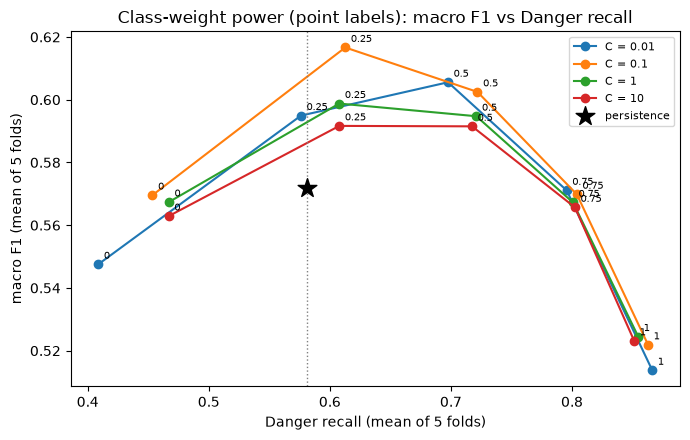

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for C, g in stage2.groupby("C"):
    ax.plot(g["danger_recall_mean"], g["macro_f1_mean"], "o-", label=f"C = {C:g}")
    for _, r in g.iterrows():
        ax.annotate(f"{r.weight_power:g}", (r.danger_recall_mean, r.macro_f1_mean), textcoords="offset points",
                    xytext=(4, 4), fontsize=7)
ax.scatter([BASE_DANGER_RECALL], [BASE_F1], marker="*", s=200, color="black", label="persistence", zorder=5)
ax.axvline(BASE_DANGER_RECALL, color="grey", ls=":", lw=1)
ax.set_xlabel("Danger recall (mean of 5 folds)")
ax.set_ylabel("macro F1 (mean of 5 folds)")
ax.set_title("Class-weight power (point labels): macro F1 vs Danger recall")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "figure_M1a_weight_tradeoff.png", dpi=200)
plt.show()

## 6. Selected Logistic Regression configuration

**Selection rule:** among the app-feasible configurations, the highest mean validation macro F1 among those whose mean Danger recall is at least the
persistence baseline's (a heat-warning model must not miss more Danger days than "tomorrow = today"). The city input is then
dropped if that does not lower macro F1 by more than one fold-SD (fewer inputs for the app).

In [8]:
grid = pd.concat([stage1.assign(stage=1), stage2.assign(stage=2)], ignore_index=True).drop_duplicates(
    subset=["feature_set", "weather", "static", "C", "weight_power"]).sort_values("macro_f1_mean", ascending=False)
grid = grid[grid.feature_set.isin(APP_FEATURE_SETS) | (grid.stage == 1)]
eligible = grid[(grid.danger_recall_mean >= BASE_DANGER_RECALL) & grid.feature_set.isin(APP_FEATURE_SETS)]
if len(eligible) == 0:
    print("No configuration reaches persistence Danger recall; selecting by macro F1 alone.")
    eligible = grid[grid.feature_set.isin(APP_FEATURE_SETS)]
sel = eligible.iloc[0]
SELECTED = {k: sel[k] for k in ["feature_set", "weather", "static", "C", "weight_power"]}
print("best with city input:", SELECTED, f"macro F1 {sel.macro_f1_mean:.3f} ± {sel.macro_f1_sd:.3f}")

no_city_row, _ = run({**SELECTED, "static": "none"})
grid = pd.concat([grid, pd.DataFrame([no_city_row]).assign(stage=3)], ignore_index=True)
if no_city_row["macro_f1_mean"] >= sel.macro_f1_mean - sel.macro_f1_sd and no_city_row["danger_recall_mean"] >= BASE_DANGER_RECALL:
    SELECTED["static"] = "none"
print(f"without city: macro F1 {no_city_row['macro_f1_mean']:.3f}, Danger recall {no_city_row['danger_recall_mean']:.3f}"
      f" -> city input '{SELECTED['static']}'")
grid = grid.sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
grid.to_csv(OUT / "cv_grid.csv", index=False)
print(f"{len(grid)} configurations tried; selected:", SELECTED)

_, res = run(SELECTED)
folds = res.folds
folds.to_csv(OUT / "selected_cv_folds.csv")
folds[["macro_f1", "accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "danger_recall",
       "danger_precision", "danger_false_alarm_rate", "qw_kappa", "roc_auc_ovr"]]

best with city input: {'feature_set': 'hi_lags', 'weather': 'full', 'static': 'city', 'C': np.float64(0.1), 'weight_power': np.float64(0.25)} macro F1 0.617 ± 0.091


without city: macro F1 0.614, Danger recall 0.595 -> city input 'none'
41 configurations tried; selected: {'feature_set': 'hi_lags', 'weather': 'full', 'static': 'none', 'C': np.float64(0.1), 'weight_power': np.float64(0.25)}


,macro_f1,accuracy,balanced_accuracy,macro_precision,macro_recall,danger_recall,danger_precision,danger_false_alarm_rate,qw_kappa,roc_auc_ovr
fold,,,,,,,,,,
1,0.570,0.826,0.584,0.576,0.584,0.571,0.662,0.028,0.656,0.918
2,0.547,0.853,0.526,0.587,0.526,0.714,0.734,0.022,0.631,0.902
3,0.538,0.825,0.525,0.552,0.525,0.608,0.729,0.033,0.600,0.890
4,0.719,0.870,0.707,0.734,0.707,0.547,0.554,0.024,0.644,0.926
5,0.694,0.874,0.646,0.806,0.646,0.533,0.545,0.029,0.690,0.947


### Validation summary vs persistence (mean ± SD over the 5 folds)

In [9]:
metrics = ["macro_f1", "accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "danger_precision",
           "danger_recall", "danger_f1", "danger_false_alarm_rate", "qw_kappa", "roc_auc_ovr"]
def pm(df, m):
    return f"{df[m].mean():.3f} ± {df[m].std(ddof=1):.3f}" if m in df else "n/a"
compare = pd.DataFrame({"Logistic Regression": [pm(folds, m) for m in metrics],
                        "Persistence baseline": [pm(base, m) for m in metrics]}, index=metrics)
compare

,Logistic Regression,Persistence baseline
macro_f1,0.614 ± 0.086,0.572 ± 0.084
accuracy,0.850 ± 0.024,0.835 ± 0.026
balanced_accuracy,0.598 ± 0.079,0.572 ± 0.084
macro_precision,0.651 ± 0.112,0.572 ± 0.083
macro_recall,0.598 ± 0.079,0.572 ± 0.084
danger_precision,0.645 ± 0.092,0.582 ± 0.073
danger_recall,0.595 ± 0.073,0.581 ± 0.073
danger_f1,0.618 ± 0.078,0.582 ± 0.073
danger_false_alarm_rate,0.027 ± 0.004,0.036 ± 0.012
qw_kappa,0.644 ± 0.033,0.633 ± 0.034


### Figure M1. Logistic Regression confusion matrix (out-of-fold validation predictions, all 5 folds)

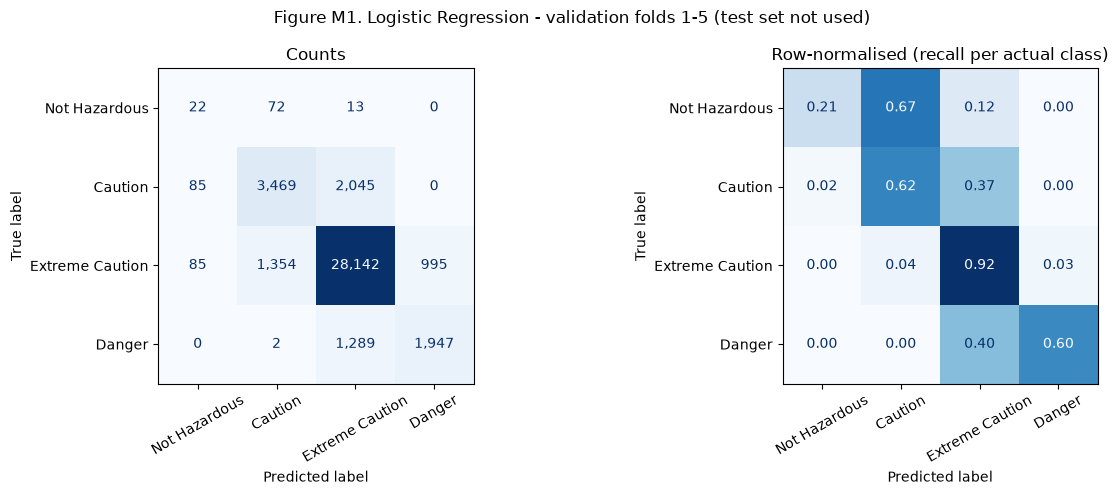

,precision,recall,f1,support
class,,,,
Not Hazardous,0.115,0.206,0.147,107
Caution,0.708,0.620,0.661,5599
Extreme Caution,0.894,0.920,0.907,30576
Danger,0.662,0.601,0.630,3238


In [10]:
cm = E.confusion_frame(res.oof_true, res.oof_pred, LABELS)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm.to_numpy(), display_labels=cm.index).plot(ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title("Counts")
norm = cm.div(cm.sum(axis=1), axis=0)
ConfusionMatrixDisplay(norm.to_numpy(), display_labels=cm.index).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title("Row-normalised (recall per actual class)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Figure M1. Logistic Regression - validation folds 1-5 (test set not used)")
fig.tight_layout()
fig.savefig(OUT / "figure_M1_confusion_matrix.png", dpi=200)
plt.show()
E.per_class_table(res.oof_true, res.oof_pred, LABELS)

## 7. Interpretation: coefficients

The selected configuration is refitted on the **training partition only** (no test rows) so its coefficients can be read.
Inputs are standardised, so a coefficient is the change in that class's log-odds per one standard deviation of the input.

In [11]:
final = make_lr(**SELECTED)
X_sel = X_for(SELECTED["feature_set"], SELECTED["weather"], SELECTED["static"])
final.fit(X_sel, y_train)
lr = final.named_steps["clf"].estimator_
names = final.named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame(lr.coef_.T, index=names, columns=[LABELS[k] for k in lr.classes_])
coef.to_csv(OUT / "coefficients.csv")
focus = LABELS[E.focus_code(LABELS)]
top = coef[focus].reindex(coef[focus].abs().sort_values(ascending=False).index).head(12)
print("class weights used:", {LABELS[k]: round(v, 2) for k, v in final.named_steps["clf"].class_weight_.items()})
top.to_frame(f"coefficient for {focus}")

class weights used: {'Not Hazardous': np.float64(3.0), 'Caution': np.float64(1.16), 'Extreme Caution': np.float64(0.75), 'Danger': np.float64(1.33)}


,coefficient for Danger
Temp_Mean,2.820
DewPoint_Mean,1.977
Temp_Max,1.271
DayOfYear_cos,-1.008
Humidity_Min,0.975
CloudCover_Mean,-0.645
RainHours,-0.618
Rainfall_Total,0.580
Temp_Min,-0.509
Humidity_Mean,0.488


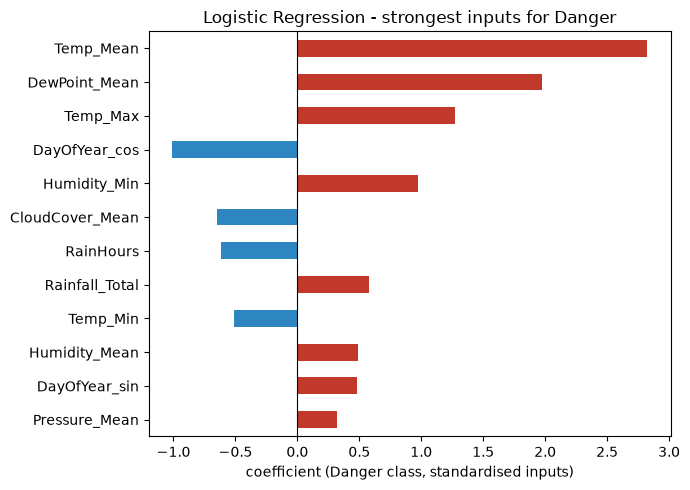

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
top[::-1].plot.barh(ax=ax, color=["#c0392b" if v > 0 else "#2e86c1" for v in top[::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel(f"coefficient ({focus} class, standardised inputs)")
ax.set_title(f"Logistic Regression - strongest inputs for {focus}")
fig.tight_layout()
fig.savefig(OUT / "figure_M1b_danger_coefficients.png", dpi=200)
plt.show()

## 8. Save the candidate model and the summary

The fitted pipeline (transformer + classifier) is saved as a **candidate**. Section 6 picks the best of the three models;
only that one goes to `models/` and is tested once on the untouched test set.

In [13]:
cand_dir = ROOT / "models" / "candidates"
cand_dir.mkdir(parents=True, exist_ok=True)
SELECTED = {k: (v.item() if hasattr(v, "item") else v) for k, v in SELECTED.items()}
joblib.dump({"pipeline": final, "config": SELECTED, "target_policy": TARGET_POLICY, "class_labels": LABELS,
             "input_columns": list(X_sel.columns), "sklearn_version": sklearn.__version__},
            cand_dir / f"logistic_regression_{TARGET_POLICY}.joblib")

summary = {"model": "Logistic Regression", "target_policy": TARGET_POLICY, "selected_config": SELECTED,
           "selection_rule": "max mean CV macro F1 subject to mean CV Danger recall >= persistence",
           "input_columns": list(X_sel.columns), "n_model_inputs_after_encoding": int(len(names)),
           "cv": {m: {"mean": float(folds[m].mean()), "sd": float(folds[m].std(ddof=1))} for m in metrics},
           "persistence_cv": {m: {"mean": float(base[m].mean()), "sd": float(base[m].std(ddof=1))}
                              for m in metrics if m in base},
           "configurations_tried": int(len(grid)), "test_set_used": False}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

saved:
  coefficients.csv
  cv_grid.csv
  figure_M1_confusion_matrix.png
  figure_M1a_weight_tradeoff.png
  figure_M1b_danger_coefficients.png
  selected_cv_folds.csv
  summary.json


## 9. Values for the workspace doc (Section 5.1)

In [14]:
cfg = SELECTED
print(f"""Hyperparameters tested ({len(grid)} configurations, same 5 folds)
  C: 0.01, 0.1, 1, 10 -> selected C = {cfg['C']:g}
  Penalty / solver: L2 with lbfgs (multinomial); L1 / elastic net with saga did not converge in practical time
  Other: class-weight power 0, 0.25, 0.5, 0.75, 1 (1 = balanced) -> selected {cfg['weight_power']:g};
         feature set '{cfg['feature_set']}', weather set '{cfg['weather']}', city input '{cfg['static']}';
         max_iter=5000, random_state=42

Results (validation, mean ± SD over 5 folds; test set not used)        persistence
  CV primary metric (macro F1)  {pm(folds, 'macro_f1'):16s}  {pm(base, 'macro_f1')}
  Accuracy                      {pm(folds, 'accuracy'):16s}  {pm(base, 'accuracy')}
  Precision (macro)             {pm(folds, 'macro_precision'):16s}  {pm(base, 'macro_precision')}
  Recall (macro)                {pm(folds, 'macro_recall'):16s}  {pm(base, 'macro_recall')}
  F1 score (macro)              {pm(folds, 'macro_f1'):16s}  {pm(base, 'macro_f1')}
  ROC-AUC (one-vs-rest, macro)  {pm(folds, 'roc_auc_ovr'):16s}  n/a
  Danger recall                 {pm(folds, 'danger_recall'):16s}  {pm(base, 'danger_recall')}
  Danger precision              {pm(folds, 'danger_precision'):16s}  {pm(base, 'danger_precision')}""")

Hyperparameters tested (41 configurations, same 5 folds)
  C: 0.01, 0.1, 1, 10 -> selected C = 0.1
  Penalty / solver: L2 with lbfgs (multinomial); L1 / elastic net with saga did not converge in practical time
  Other: class-weight power 0, 0.25, 0.5, 0.75, 1 (1 = balanced) -> selected 0.25;
         feature set 'hi_lags', weather set 'full', city input 'none';
         max_iter=5000, random_state=42

Results (validation, mean ± SD over 5 folds; test set not used)        persistence
  CV primary metric (macro F1)  0.614 ± 0.086     0.572 ± 0.084
  Accuracy                      0.850 ± 0.024     0.835 ± 0.026
  Precision (macro)             0.651 ± 0.112     0.572 ± 0.083
  Recall (macro)                0.598 ± 0.079     0.572 ± 0.084
  F1 score (macro)              0.614 ± 0.086     0.572 ± 0.084
  ROC-AUC (one-vs-rest, macro)  0.917 ± 0.022     n/a
  Danger recall                 0.595 ± 0.073     0.581 ± 0.073
  Danger precision              0.645 ± 0.092     0.582 ± 0.073
